[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/hyperspectral-course-2026/blob/main/12_processing_workflow.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# ⚙️ Hyperspectral Image Processing Workflows
### Space Academy 2026 · Hyperspectral course · Week 2 — Hyperspectral image processing workflows (Lecture + Practical)

The theme notebooks (00–06) walk through the same 12 steps again and again: load a STAC item, download the HDF5, check the masks, pick bands, compute indices, plot. That's fine for learning, but a project needs a **workflow**: a repeatable chain of processing steps that runs on any scene, any area, any number of times, and gives the same answer every time.

This notebook turns those copy-pasted cells into a small, configurable pipeline. You will run it on one scene, then on every course scene in a batch, then on a full scene tile by tile so it never runs out of memory.

**What you will learn**
- Why a *workflow* beats a pile of notebook cells, and what a good processing chain looks like
- How the course helper module `hsi_utils.py` is organised, and how it maps onto that chain
- How to drive a pipeline from a **configuration dictionary** (no more editing code to change a parameter)
- How to export analysis-ready results: a **Cloud-Optimised GeoTIFF** plus a **JSON provenance sidecar**
- How to **batch-process** several scenes and summarise them in one table
- How to process a full scene **tile by tile** (memory-aware) instead of loading 1 GB into RAM
- The basics of **reproducibility**: seeds, software versions, logging, idempotent outputs

**Prerequisites:** `00_EO_data_quickstart_notebook.ipynb` (STAC, HDF5, indices) and `11_preprocessing.ipynb` (masks and bad bands).

**Data:** all course scenes, mainly Konya, Türkiye (`20250608_091605_90_4001`). `hu.get_scene()` uses a local copy of the HDF5 if it finds one (in `data/`, in `../notebooks/` or in the current folder) and otherwise downloads it (~1 GB) from Planet's open STAC catalogue. In the batch section, scenes that aren't on disk are skipped rather than downloaded.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90

## 1. From a pile of cells to a workflow

Look at the six theme notebooks side by side and you'll find the same code in each, with small differences: a different threshold, a different band, a mask that is applied in one notebook and forgotten in another. That's how bugs and irreproducible results start.

A **workflow** (or *processing chain*) has three properties:

| Property | What it means in practice |
|---|---|
| **Parameterised** | Everything that can change (scene, area, bands, thresholds) lives in one configuration object, not scattered through the code. |
| **Modular** | Each step is a function with clear inputs and outputs, so you can test, reuse or replace it on its own. |
| **Traceable** | Every output records *how* it was made (input scene, parameters, software versions), so you or a reviewer can reproduce it months later. |

The course processing chain looks like this, with the `hsi_utils` function that does each step:

```
 ┌──────────────┐   ┌──────────────┐   ┌──────────────┐   ┌──────────────┐   ┌──────────────┐   ┌──────────────┐
 │ 1. FIND/LOAD │──▶│ 2. QA MASKS  │──▶│ 3. BAD BANDS │──▶│ 4. SUBSET    │──▶│ 5. ANALYSE   │──▶│ 6. EXPORT    │
 │ STAC / HDF5  │   │ nodata/cloud │   │ H2O, SWIR    │   │ window/tiles │   │ indices, SAM │   │ COG + JSON   │
 └──────────────┘   └──────────────┘   └──────────────┘   └──────────────┘   └──────────────┘   └──────────────┘
  hu.get_scene       scene.masks        hu.good_band_mask   window=(r0,r1,     hu.nd,              hu.save_geotiff
  hu.fetch_item      scene.valid_mask   scene.good_bands     c0,c1), stride    hu.spectral_angle   + provenance JSON
  hu.download        scene.summary()                         scene.read_cube   hu.band_depth
```

`hsi_utils` is organised the same way: *paths and catalogue* → *STAC access* → *band helpers* → the `TanagerScene` reader → *array helpers* → *spectral operations* → *export*. Open `hsi_utils.py` in an editor; it's meant to be read.

## 2. The building blocks

A `TanagerScene` opens the HDF5 **lazily**: opening it reads only the metadata. Pixel values are loaded when you ask for a band, a pixel or a window, which is why opening a 1 GB file takes milliseconds.

In [2]:
scene = hu.get_scene("20250608_091605_90_4001")
print(scene)
print(scene.summary())
print("\nAuxiliary fields in the file:", scene.field_names)

TanagerScene(20250608_091605_90_4001, 673×776 px, 426 bands)
Scene      : 20250608_091605_90_4001  (Konya, Türkiye)
File       : /home/course/notebooks/20250608_091605_90_4001_ortho_sr_hdf5.h5
Cube       : 426 bands × 673 rows × 776 cols
Wavelengths: 376–2499 nm, FWHM 5.2–6.8 nm
Good bands : 352 of 426
Grid       : EPSG:32636, 30 m pixels
No-data    : 30.4%   cloud flag: 1.2%   cirrus flag: 0.0%   usable: 68.4%

Auxiliary fields in the file: ['aerosol_optical_depth', 'beta_cirrus_mask', 'beta_cloud_mask', 'column_water_vapour', 'nodata_pixels', 'sensor_azimuth', 'sensor_to_ground_path_length', 'sensor_zenith', 'sun_azimuth', 'sun_zenith', 'surface_reflectance', 'surface_reflectance_uncertainty', 'time']


## 3. A configuration-driven pipeline

All the parameters for one run go into a single dictionary. To process another area you change the **configuration**, not the code. In a real project you would keep the configuration in a YAML or JSON file under version control.

Each index here is a normalised difference $(R_a - R_b)/(R_a + R_b)$, defined by its two wavelengths in nm.

In [3]:
from pathlib import Path

CONFIG = {
    "scene_id": "20250608_091605_90_4001",   # Konya, Türkiye
    "window": (300, 500, 400, 600),           # (row_start, row_stop, col_start, col_stop); None = whole scene
    "mask_cloud": True,                       # apply the beta cloud mask
    "min_valid_fraction": 0.5,                # QA gate: refuse windows that are mostly no-data/cloud
    "indices": {                              # name: (band_a_nm, band_b_nm) → (a − b) / (a + b)
        "NDVI": (860, 665),                   # vegetation greenness
        "NDRE": (860, 705),                   # red-edge chlorophyll
        "NDWI": (560, 860),                   # open water (McFeeters 1996)
        "NDMI": (860, 1650),                  # canopy moisture
        "NBR":  (860, 2200),                  # burn ratio / dry matter
    },
    "output_dir": str(hu.ensure_output_dir("12")),
    "overwrite": True,
}
CONFIG

{'scene_id': '20250608_091605_90_4001',
 'window': (300, 500, 400, 600),
 'mask_cloud': True,
 'min_valid_fraction': 0.5,
 'indices': {'NDVI': (860, 665),
  'NDRE': (860, 705),
  'NDWI': (560, 860),
  'NDMI': (860, 1650),
  'NBR': (860, 2200)},
 'output_dir': '/home/course/hyperspectral_course_notebooks/outputs/12',
 'overwrite': True}

### 3.1 Logging instead of `print`

A pipeline that runs unattended (on a server, overnight, over 50 scenes) needs a **log**: time-stamped messages that go both to the screen and to a file, so you can check afterwards what happened.

In [4]:
import logging
import sys

def get_logger(name="hsi_pipeline", logfile=None):
    """Logger that writes to the notebook and (optionally) to a file, without duplicate handlers."""
    log = logging.getLogger(name)
    log.setLevel(logging.INFO)
    log.propagate = False
    fmt = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
    if not log.handlers:
        h = logging.StreamHandler(sys.stdout)
        h.setFormatter(fmt)
        log.addHandler(h)
    if logfile and not any(isinstance(h, logging.FileHandler) for h in log.handlers):
        fh = logging.FileHandler(logfile)
        fh.setFormatter(fmt)
        log.addHandler(fh)
    return log

log = get_logger(logfile=Path(CONFIG["output_dir"]) / "pipeline.log")
log.info("Logger ready")

10:38:12 | INFO    | Logger ready


### 3.2 The steps as functions

Every step takes the configuration (and the output of the previous step) and returns something the next step can
use. The QA step acts as a **gate**: if too few pixels are usable, the pipeline stops with a clear message instead
of quietly producing a map of NaNs.

> **What this section is really teaching.** The next few cells contain almost no hyperspectral science — the index
> maths is three lines, and you already know it from Sentinel-2. What they teach is **reproducible workflow
> habits**: splitting a job into testable steps, refusing bad input early, and recording how each output was made.
> That is what makes a result defensible six months later, and it is the same whether the cube has 10 bands or 350.

We build the pipeline one piece at a time — **load → QA gate → indices → provenance → export** — and finish with a
small runner that calls them in order.

#### Steps 1–2: load the scene, then check it is worth processing

`step_load` opens the scene; `step_qa` measures how much of the window is usable and **raises** if it is below
`min_valid_fraction`. Failing loudly here is the whole point: the alternative is a beautiful map of NaNs.

In [5]:
import json
import time


def step_load(cfg):
    scene = hu.get_scene(cfg["scene_id"])
    log.info(f"Loaded {scene.scene_id} ({scene.info.get('place', '?')}) from {scene.path.name}")
    return scene


def step_qa(scene, cfg):
    m = scene.masks(cfg["window"])
    valid = scene.valid_mask(cfg["window"], cloud=cfg["mask_cloud"])
    qa = {"valid_fraction": float(valid.mean()),
          "nodata_fraction": float(m["nodata"].mean()),
          "cloud_flag_fraction": float(m["cloud"].mean()),
          "cirrus_flag_fraction": float(m["cirrus"].mean())}
    log.info("QA: " + ", ".join(f"{k}={v:.3f}" for k, v in qa.items()))
    if qa["valid_fraction"] < cfg["min_valid_fraction"]:
        raise ValueError(f"Only {qa['valid_fraction']:.0%} valid pixels — below the QA gate "
                         f"of {cfg['min_valid_fraction']:.0%}. Choose another window or scene.")
    return valid, qa

#### Step 3: the indices

The familiar part. Each band is read once and reused across the indices that need it, and the QA mask is applied
at the end so every output shares exactly the same valid pixels. `used` records the **actual** band centres chosen
(860 nm is not exactly 860 nm), which goes into the sidecar — your Sentinel-2 workflow never had to think about
this because the band centres were fixed.

In [6]:
def step_indices(scene, cfg, valid):
    bands_needed = sorted({nm for pair in cfg["indices"].values() for nm in pair})
    # read each band once, without masking; the QA mask is applied below
    bands = {nm: scene.read_band(nm, cfg["window"], mask=False) for nm in bands_needed}
    used = {nm: round(float(scene.wavelengths[scene.band_index(nm)]), 2) for nm in bands_needed}
    out = {}
    for name, (a, b) in cfg["indices"].items():
        idx = hu.nd(bands[a], bands[b]).astype("float32")
        idx[~valid] = np.nan
        out[name] = idx
    log.info(f"Computed {len(out)} indices from {len(bands_needed)} bands")
    return out, used

#### Provenance: the cell you may skim

These two helpers fill in the "how was this made" part of the sidecar: the versions of the libraries involved, and
a short fingerprint (SHA-256) of `hsi_utils.py` so a result can be tied to the exact helper code that produced it.

**This is bookkeeping, not science.** It earns its place for one reason: a map with no record of the code,
parameters and data that produced it cannot be reproduced or defended — and the project rubric asks for exactly
that. Run the cell, note what comes out, and move on.

In [7]:
import hashlib
import platform
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError


def software_versions():
    """What produced this result: library versions plus a fingerprint of hsi_utils.py."""
    out = {"python": platform.python_version()}
    for pkg in ("numpy", "h5py", "rasterio", "scipy", "scikit-learn", "xarray"):
        try:
            out[pkg] = version(pkg)
        except PackageNotFoundError:
            out[pkg] = None
    out["hsi_utils_sha256"] = hashlib.sha256(Path(hu.__file__).read_bytes()).hexdigest()[:12]
    return out


def acquisition_time(scene_id):
    """Tanager IDs start with the UTC acquisition time: YYYYMMDD_HHMMSS_…"""
    return datetime.strptime(scene_id[:15], "%Y%m%d_%H%M%S").replace(tzinfo=timezone.utc).isoformat()


software_versions()          # this dictionary ends up inside every sidecar

{'python': '3.13.13',
 'numpy': '2.5.3',
 'h5py': '3.16.0',
 'rasterio': '1.5.2',
 'scipy': '1.18.1',
 'scikit-learn': '1.9.1',
 'xarray': '2026.9.0',
 'hsi_utils_sha256': '01ac7a53560f'}

#### Step 4: export the product and its sidecar

One GeoTIFF with named bands, one JSON file beside it holding everything needed to recreate it. The
`overwrite=False` branch is what makes re-running the pipeline safe (section 3.4).

In [8]:
def step_export(scene, cfg, indices, qa, bands_used):
    out_dir = Path(cfg["output_dir"])
    stem = f"{scene.scene_id}_indices"
    tif, sidecar = out_dir / f"{stem}.tif", out_dir / f"{stem}.json"
    if tif.exists() and not cfg["overwrite"]:
        log.info(f"{tif.name} already exists and overwrite=False → skipped (idempotent run)")
        return tif, sidecar
    names = list(indices)
    transform = scene.transform(cfg["window"])
    hu.save_geotiff(tif, np.stack([indices[n] for n in names]), transform, scene.crs, band_names=names)
    provenance = {
        "product": "Tanager spectral indices",
        "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "scene_id": scene.scene_id,
        "acquired_utc": acquisition_time(scene.scene_id),
        "place": scene.info.get("place"),
        "source_file": scene.path.name,
        "crs": scene.crs,
        "geotransform": list(transform)[:6],
        "bands_in_output": names,
        "band_centres_used_nm": bands_used,
        "qa": qa,
        "config": cfg,
        "software": software_versions(),
        "attribution": hu.attribution(scene.scene_id),
    }
    sidecar.write_text(json.dumps(provenance, indent=2, default=str))
    log.info(f"Wrote {tif.name} ({tif.stat().st_size / 1e3:.0f} kB) and {sidecar.name}")
    return tif, sidecar

#### The runner

Nine lines that call the steps in order and time the run. This is the only function you call by hand, and the only
one a scheduler or a colleague needs to know about.

In [9]:
def run_pipeline(cfg):
    t0 = time.perf_counter()
    log.info(f"=== Pipeline start: {cfg['scene_id']} window={cfg['window']} ===")
    scene = step_load(cfg)
    valid, qa = step_qa(scene, cfg)
    indices, used = step_indices(scene, cfg, valid)
    tif, sidecar = step_export(scene, cfg, indices, qa, used)
    log.info(f"=== Done in {time.perf_counter() - t0:.1f} s ===")
    return {"scene": scene, "indices": indices, "qa": qa, "tif": tif, "sidecar": sidecar}


result = run_pipeline(CONFIG)

10:38:13 | INFO    | === Pipeline start: 20250608_091605_90_4001 window=(300, 500, 400, 600) ===


10:38:13 | INFO    | Loaded 20250608_091605_90_4001 (Konya, Türkiye) from 20250608_091605_90_4001_ortho_sr_hdf5.h5


10:38:13 | INFO    | QA: valid_fraction=0.999, nodata_fraction=0.000, cloud_flag_fraction=0.001, cirrus_flag_fraction=0.000


10:38:13 | INFO    | Computed 5 indices from 6 bands


10:38:13 | INFO    | Wrote 20250608_091605_90_4001_indices.tif (626 kB) and 20250608_091605_90_4001_indices.json


10:38:13 | INFO    | === Done in 0.5 s ===


### 3.3 Check the outputs

A good habit is to **re-open the exported file** and check its CRS, geotransform and band names, rather than trusting that the write succeeded. The sidecar JSON records the processing history ("lineage") of the product.

Driver     : GTiff | layout: COG
Size       : 5 bands × 200 × 200
CRS        : EPSG:32636
Transform  : (30.0, 0.0, 462750.0, 0.0, -30.0, 4163100.0)
Band names : ('NDVI', 'NDRE', 'NDWI', 'NDMI', 'NBR')


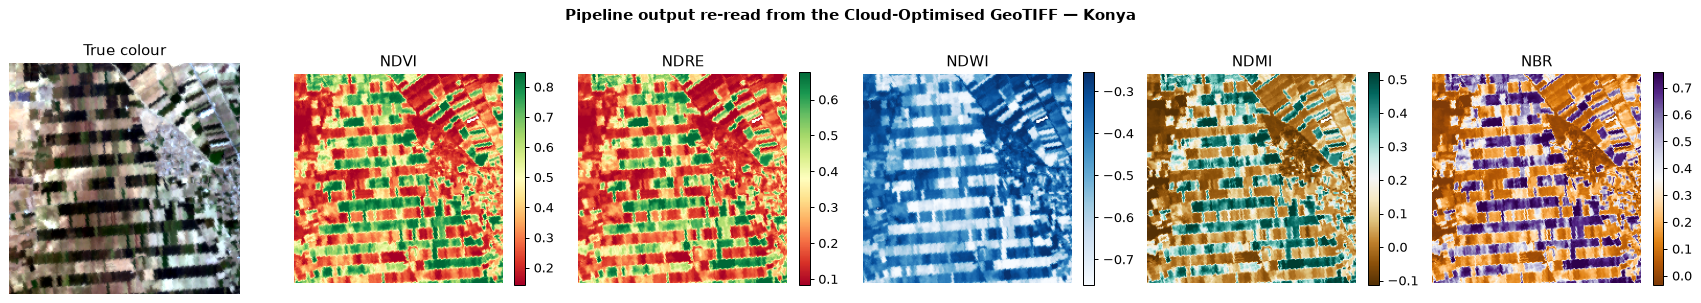

In [10]:
import rasterio

with rasterio.open(result["tif"]) as src:
    print("Driver     :", src.driver, "| layout:", src.tags(ns="IMAGE_STRUCTURE").get("LAYOUT"))
    print("Size       :", src.count, "bands ×", src.height, "×", src.width)
    print("CRS        :", src.crs)
    print("Transform  :", tuple(round(v, 2) for v in src.transform[:6]))
    print("Band names :", src.descriptions)
    exported = src.read()

fig, axes = plt.subplots(1, len(src.descriptions) + 1, figsize=(19, 3.6))
axes[0].imshow(result["scene"].rgb(CONFIG["window"]))
axes[0].set_title("True colour")
cmaps = {"NDVI": "RdYlGn", "NDRE": "RdYlGn", "NDWI": "Blues", "NDMI": "BrBG", "NBR": "PuOr"}
for ax, band, name in zip(axes[1:], exported, src.descriptions):
    im = ax.imshow(band, cmap=cmaps.get(name, "viridis"), vmin=np.nanpercentile(band, 2), vmax=np.nanpercentile(band, 98))
    ax.set_title(name)
    plt.colorbar(im, ax=ax, fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.suptitle("Pipeline output re-read from the Cloud-Optimised GeoTIFF — Konya", fontweight="bold")
plt.tight_layout(); plt.show()

In [11]:
sidecar = json.loads(result["sidecar"].read_text())
print(json.dumps({k: sidecar[k] for k in ("scene_id", "acquired_utc", "crs", "geotransform",
                                          "band_centres_used_nm", "qa", "software", "attribution")}, indent=2))

{
  "scene_id": "20250608_091605_90_4001",
  "acquired_utc": "2025-06-08T09:16:05+00:00",
  "crs": "EPSG:32636",
  "geotransform": [
    30.0,
    0.0,
    462750.0,
    0.0,
    -30.0,
    4163100.0
  ],
  "band_centres_used_nm": {
    "560": 560.83,
    "665": 665.87,
    "705": 705.92,
    "860": 861.26,
    "1650": 1647.66,
    "2200": 2201.22
  },
  "qa": {
    "valid_fraction": 0.999275,
    "nodata_fraction": 0.0,
    "cloud_flag_fraction": 0.000725,
    "cirrus_flag_fraction": 0.0
  },
  "software": {
    "python": "3.13.13",
    "numpy": "2.5.3",
    "h5py": "3.16.0",
    "rasterio": "1.5.2",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "xarray": "2026.9.0",
    "hsi_utils_sha256": "01ac7a53560f"
  },
  "attribution": "Tanager STAC Data, available at www.planet.com/data/stac \u00a9 2025 Planet Labs PBC. CC-BY-4.0"
}


### 3.4 Idempotent re-runs

Running a step twice with the same input should give the same result, and it shouldn't redo expensive work unless you ask it to. With `overwrite=False` the export step sees the existing file and skips it.

In [12]:
cfg_again = dict(CONFIG, overwrite=False)
_ = run_pipeline(cfg_again)

10:38:13 | INFO    | === Pipeline start: 20250608_091605_90_4001 window=(300, 500, 400, 600) ===


10:38:13 | INFO    | Loaded 20250608_091605_90_4001 (Konya, Türkiye) from 20250608_091605_90_4001_ortho_sr_hdf5.h5


10:38:13 | INFO    | QA: valid_fraction=0.999, nodata_fraction=0.000, cloud_flag_fraction=0.001, cirrus_flag_fraction=0.000


10:38:13 | INFO    | Computed 5 indices from 6 bands


10:38:13 | INFO    | 20250608_091605_90_4001_indices.tif already exists and overwrite=False → skipped (idempotent run)


10:38:13 | INFO    | === Done in 0.1 s ===


And here is the QA gate at work: a window in the no-data corner of the rotated footprint is rejected with a readable message.

In [13]:
try:
    run_pipeline(dict(CONFIG, window=(0, 100, 0, 100)))
except ValueError as err:
    log.warning(f"Pipeline stopped by QA gate: {err}")

10:38:13 | INFO    | === Pipeline start: 20250608_091605_90_4001 window=(0, 100, 0, 100) ===


10:38:13 | INFO    | Loaded 20250608_091605_90_4001 (Konya, Türkiye) from 20250608_091605_90_4001_ortho_sr_hdf5.h5


10:38:13 | INFO    | QA: valid_fraction=0.011, nodata_fraction=0.989, cloud_flag_fraction=0.000, cirrus_flag_fraction=0.000


10:38:13 | WARNING | Pipeline stopped by QA gate: Only 1% valid pixels — below the QA gate of 50%. Choose another window or scene.


## 4. Batch processing all course scenes

Once each step is a function, running the chain over many scenes is a loop. The batch below:
- opens every course scene that is **available locally** and skips the rest with a log message (no surprise 1 GB downloads),
- computes QA statistics and scene-wide index means on a **strided** read (every 2nd pixel, which is plenty for statistics),
- collects everything in a `pandas` table you can sort, filter and save as CSV.

In [14]:
import pandas as pd

rows, previews = [], {}
for sid, info in hu.SCENES.items():
    try:
        sc = hu.get_scene(sid, download_if_missing=False)
    except FileNotFoundError:
        log.info(f"skip {sid} ({info['place']}): not on disk")
        continue
    t0 = time.perf_counter()
    stride = 2
    m = sc.masks(stride=stride)
    valid = sc.valid_mask(stride=stride)
    b = {nm: sc.read_band(nm, stride=stride) for nm in (560, 665, 860, 2200)}
    ndvi, ndwi, nbr = hu.nd(b[860], b[665]), hu.nd(b[560], b[860]), hu.nd(b[860], b[2200])
    rows.append({
        "scene_id": sid, "place": info["place"], "acquired": sid[:8],
        "valid_%": 100 * valid.mean(),
        "nodata_%": 100 * m["nodata"].mean(),
        "cloud_flag_%_of_footprint": 100 * (m["cloud"] & ~m["nodata"]).sum() / (~m["nodata"]).sum(),
        "mean_NDVI": np.nanmean(ndvi), "mean_NDWI": np.nanmean(ndwi), "mean_NBR": np.nanmean(nbr),
        "water_%": 100 * np.nanmean(ndwi > 0.0), "green_veg_%": 100 * np.nanmean(ndvi > 0.5),
        "seconds": time.perf_counter() - t0,
    })
    previews[sid] = sc.rgb(stride=3)
    log.info(f"{sid} done in {rows[-1]['seconds']:.1f} s")

summary = pd.DataFrame(rows).set_index("scene_id")
summary.to_csv(Path(CONFIG["output_dir"]) / "batch_summary.csv")
summary.round(2)

10:38:16 | INFO    | 20241215_185916_33_4001 done in 0.4 s


10:38:17 | INFO    | 20250123_185518_92_4001 done in 0.7 s


10:38:18 | INFO    | 20250219_053251_31_4001 done in 0.6 s


10:38:18 | INFO    | 20250223_165546_32_4001 done in 0.4 s


10:38:19 | INFO    | 20250407_035509_25_4001 done in 0.4 s


10:38:20 | INFO    | 20250511_074311_00_4001 done in 0.5 s


10:38:21 | INFO    | 20250608_091605_90_4001 done in 0.4 s


,place,acquired,valid_%,nodata_%,cloud_flag_%_of_footprint,mean_NDVI,mean_NDWI,mean_NBR,water_%,green_veg_%,seconds
scene_id,,,,,,,,,,,
20241215_185916_33_4001,"Malibu, California, USA",20241215,71.19,28.80,0.01,0.08,0.14,0.31,42.47,18.26,0.43
20250123_185518_92_4001,"Santa Monica Mountains, California, USA",20250123,67.02,31.65,0.06,0.05,0.12,0.17,30.35,8.23,0.70
20250219_053251_31_4001,"Korba, Chhattisgarh, India",20250219,72.56,27.44,0.00,0.23,-0.21,0.05,3.24,1.07,0.56
20250223_165546_32_4001,"Usulután, El Salvador",20250223,72.02,27.97,0.01,0.50,-0.37,0.46,20.44,43.86,0.41
20250407_035509_25_4001,"Ho Chi Minh City, Vietnam",20250407,66.34,27.40,0.64,0.36,-0.28,0.27,5.94,18.96,0.42
20250511_074311_00_4001,"Al Dhafra coast, UAE",20250511,38.58,20.89,51.23,-0.37,0.64,0.46,36.37,0.00,0.48
20250608_091605_90_4001,"Konya, Türkiye",20250608,68.62,30.23,1.64,0.29,-0.37,0.14,0.00,9.57,0.40


**Read the table like a QA analyst.** One scene should jump out: **Al Dhafra (UAE)** has a very high cloud-flag percentage, yet the true-colour quicklook below is almost cloud-free. The `beta_cloud_mask` confuses bright, white **sabkha** (salt flat) with cloud. If a pipeline trusted that mask blindly, half of the scene's land would vanish. Notebook 11 looks at this in detail. The lesson for workflows: **always look at a summary table and at quicklooks before trusting batch results.**

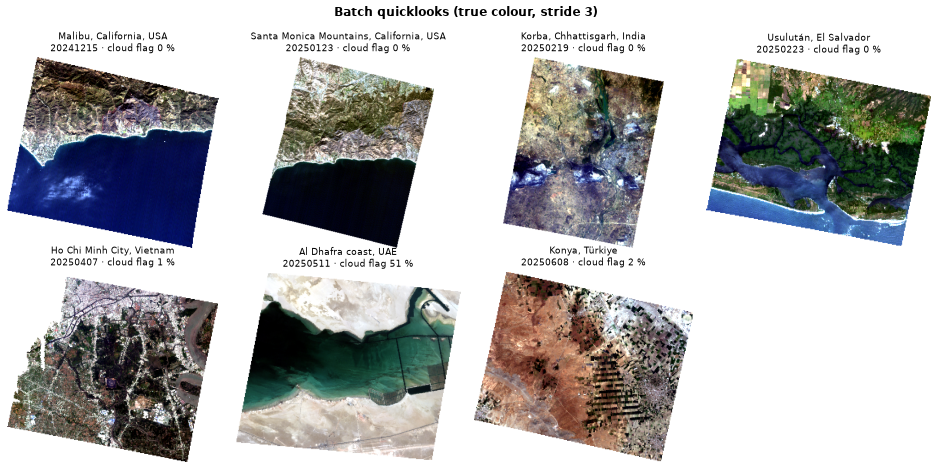

In [15]:
n = len(previews)
ncols = min(4, n)
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.4 * nrows), dpi=70)
axes = np.atleast_1d(axes).ravel()
for ax, (sid, rgb) in zip(axes, previews.items()):
    rgb = rgb.copy()
    rgb[np.isnan(rgb)] = 1.0
    ax.imshow(rgb)
    ax.set_title(f"{hu.SCENES[sid]['place']}\n{sid[:8]} · cloud flag {summary.loc[sid, 'cloud_flag_%_of_footprint']:.0f} %",
                 fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle("Batch quicklooks (true colour, stride 3)", fontweight="bold")
plt.tight_layout(); plt.show()

## 5. Tiled processing: full resolution without running out of memory

Some analyses need **every band of every pixel**, for example the spectral angle between each pixel and a reference spectrum (notebook 14). How much memory would a full cube need?

In [16]:
b, h, w = scene.shape
print(f"Full cube: {b} bands × {h} × {w} px × 4 bytes = {b * h * w * 4 / 1e9:.2f} GB (float32)")
print("…and numpy often makes one or two temporary copies during a calculation.")
print(f"A 256 × 256 tile: {b * 256 * 256 * 4 / 1e6:.0f} MB")

Full cube: 426 bands × 673 × 776 px × 4 bytes = 0.89 GB (float32)
…and numpy often makes one or two temporary copies during a calculation.
A 256 × 256 tile: 112 MB


On a laptop or a free Colab instance (12 GB RAM), several GB per scene is a problem, and a larger scene or a stack of scenes won't fit at all. Two standard ways out:

1. **Strided preview**: read every *n*-th row and column (`stride=n`). It's fast and good for exploring, but you lose resolution.
2. **Tiling**: cut the scene into tiles, process each one completely, and write the result into a full-size output array. Peak memory is one tile, and you keep full resolution.

A Python **generator** is the natural way to walk over tiles: it hands out one window at a time, and the tiles can be read in parallel or on a cluster later.

As a full-spectrum product we compute the **spectral angle** (SAM) between each pixel and the *irrigated crop* reference spectrum from the course library (notebook 10): a small angle means "spectrally similar to a green irrigated crop".

In [17]:
def iter_tiles(n_rows, n_cols, tile=256):
    """Yield (row_start, row_stop, col_start, col_stop) windows that cover the grid."""
    for r0 in range(0, n_rows, tile):
        for c0 in range(0, n_cols, tile):
            yield (r0, min(r0 + tile, n_rows), c0, min(c0 + tile, n_cols))


# Reference spectrum from the course library, interpolated onto this scene's good bands
lib_wl, lib, lib_meta = hu.load_library()
good_wl = scene.wavelengths[scene.good_bands]
ref = np.interp(good_wl, lib_wl, lib["irrigated_crop"])
use = np.isfinite(ref)              # bands present in both the scene and the library


def sam_of_window(sc, window, stride=1):
    cube, _ = sc.read_cube(window, stride=stride)          # good bands, NaN-masked
    X, ok = hu.cube_to_pixels(cube[use])
    out = hu.pixels_to_image(np.degrees(hu.spectral_angle(X, ref[use])), ok) if ok.any() else np.full(ok.shape, np.nan)
    return out.astype("float32")


tiles = list(iter_tiles(h, w, tile=256))
print(f"{len(tiles)} tiles of up to 256 × 256 px")

12 tiles of up to 256 × 256 px


In [18]:
import tracemalloc

sam_full = np.full((h, w), np.nan, dtype="float32")
tracemalloc.start()
t0 = time.perf_counter()
skipped = 0
for win in tiles:
    r0, r1, c0, c1 = win
    if not scene.valid_mask(win).any():     # cheap check first: skip tiles that are all no-data
        skipped += 1
        continue
    sam_full[r0:r1, c0:c1] = sam_of_window(scene, win)
t_tiled = time.perf_counter() - t0
_, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()
print(f"Tiled full resolution: {t_tiled:.1f} s, {skipped} empty tiles skipped, peak Python memory ≈ {peak / 1e6:.0f} MB")

t0 = time.perf_counter()
sam_preview = sam_of_window(scene, None, stride=4)
t_preview = time.perf_counter() - t0
print(f"Strided preview (stride 4): {t_preview:.1f} s, {sam_preview.shape[0]} × {sam_preview.shape[1]} px")

Tiled full resolution: 4.3 s, 2 empty tiles skipped, peak Python memory ≈ 368 MB


Strided preview (stride 4): 3.2 s, 169 × 194 px


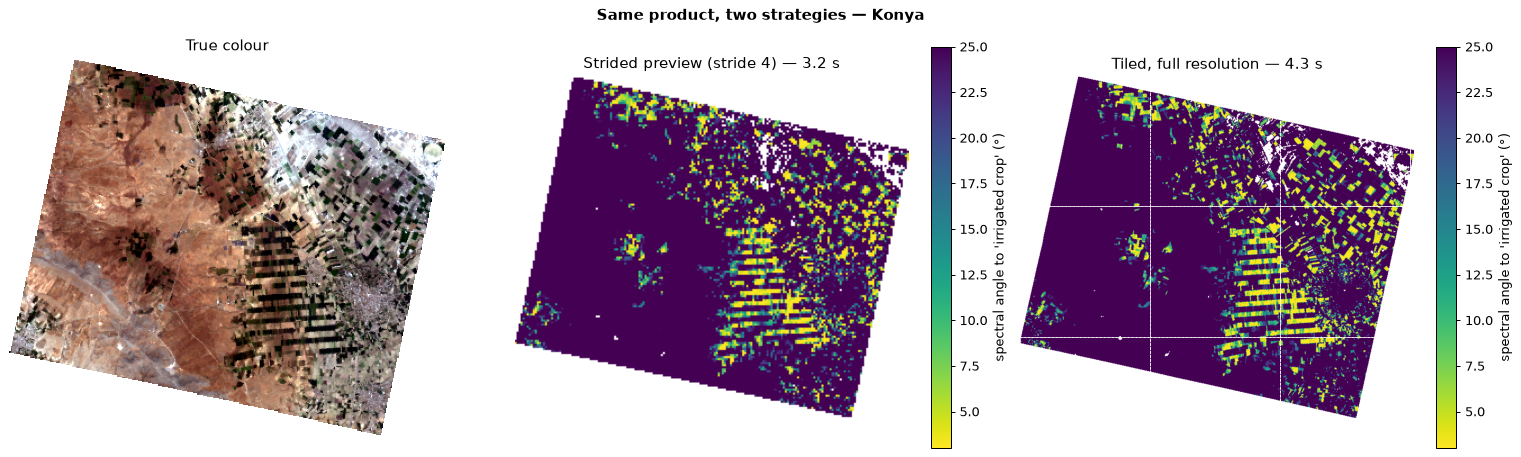

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
axes[0].imshow(scene.rgb(stride=2)); axes[0].set_title("True colour")
for ax, img, title in ((axes[1], sam_preview, f"Strided preview (stride 4) — {t_preview:.1f} s"),
                       (axes[2], sam_full, f"Tiled, full resolution — {t_tiled:.1f} s")):
    im = ax.imshow(img, cmap="viridis_r", vmin=3, vmax=25)
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, label="spectral angle to 'irrigated crop' (°)")
for ax in axes:
    ax.axis("off")
# tile grid for illustration
for r0, r1, c0, c1 in tiles:
    axes[2].add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), c1 - c0, r1 - r0, fill=False, ec="white", lw=0.6, ls="--"))
plt.suptitle("Same product, two strategies — Konya", fontweight="bold")
plt.tight_layout(); plt.show()

Small angles (yellow) match the irrigated fields almost perfectly: the pipeline found every field that looks spectrally like the reference crop.

**Why is the strided preview barely faster?** Tanager HDF5 files are stored in compressed *chunks* (14 bands × 44 × 49 px). To read every 4th pixel, h5py still has to decompress **every** chunk. Striding saves memory, not disk I/O. Tiling costs about the same time at full resolution. For truly fast previews use the `ortho_visual` COG (notebook 00) or the subsets made with `tools/make_subsets.py`. The dashed lines are tile boundaries. Because SAM is a **per-pixel** operation there are no seams. Operations that look at **neighbouring pixels** (filters, texture, the noise estimate for MNF in notebook 13, CNN patches in notebook 20) need tiles that **overlap** by a small *halo*, otherwise you get visible seams. That's exercise 3 below.

## 6. Optional: xarray and dask

- **`xarray`** attaches coordinates (wavelength, x, y) and a CRS to the array, so you can select by *wavelength* instead of band index and export with one call.
- **`dask`** splits an array into chunks and builds a *lazy* computation graph. Nothing is read until you call `.compute()`, and then dask processes chunk by chunk, possibly in parallel. It does the tiling for you.

The dask part only runs if `dask` is installed (`pip install dask`).

In [20]:
da = scene.to_xarray(CONFIG["window"])          # DataArray (wavelength, y, x) with CRS
print(da.dims, da.shape, "| CRS:", da.rio.crs if hasattr(da, "rio") else da.attrs.get("crs"))

red, nir = da.sel(wavelength=665, method="nearest"), da.sel(wavelength=860, method="nearest")
ndvi_xr = (nir - red) / (nir + red)
print("NDVI via xarray — mean:", float(ndvi_xr.mean()))

mean_spectrum = da.mean(dim=("y", "x"))          # label-based reductions
print("Reflectance at 1650 nm (window mean):", float(mean_spectrum.sel(wavelength=1650, method="nearest")))

('wavelength', 'y', 'x') (352, 200, 200) | CRS: EPSG:32636
NDVI via xarray — mean: 0.4309227168560028
Reflectance at 1650 nm (window mean): 0.304924875497818


In [21]:
try:
    import dask.array as dsa
    import h5py
    with h5py.File(scene.path, "r") as f:
        sr = f[hu.H5_ROOT + "/surface_reflectance"]
        lazy = dsa.from_array(sr, chunks=(sr.shape[0], 128, 128))   # nothing is read yet
        good = np.where(scene.good_bands)[0]
        albedo = dsa.where(lazy[good] < -1, np.nan, lazy[good]).mean(axis=0)
        print(lazy)
        t0 = time.perf_counter()
        albedo_img = albedo.compute()          # dask now reads and reduces chunk by chunk
        print(f"Full-scene mean reflectance computed lazily in {time.perf_counter() - t0:.1f} s, shape {albedo_img.shape}")
except ImportError:
    print("dask is not installed — skip this cell or run `pip install dask` to try lazy, chunked processing.")

dask is not installed — skip this cell or run `pip install dask` to try lazy, chunked processing.


## 7. Reproducibility checklist

A result you can't reproduce isn't a result. For every analysis in your project:

| ✔ | Practice | How |
|---|---|---|
| ☐ | **Pin versions** | `requirements.txt` with versions; print them (below) and store them in the sidecar |
| ☐ | **Seed randomness** | pass `np.random.default_rng(SEED)` and `random_state=SEED` explicitly (sampling, k-means, random forests, train/test splits) |
| ☐ | **Config, not constants** | one config dict/file per run, saved next to the output |
| ☐ | **Provenance** | JSON sidecar: input scene ID, parameters, software versions, date, attribution |
| ☐ | **Log** | log file per run; warnings for skipped scenes and QA failures |
| ☐ | **Idempotent** | re-running doesn't change or duplicate outputs |
| ☐ | **Restart & Run All** | before submitting, restart the kernel and run all cells top to bottom |
| ☐ | **Relative paths** | no `/Users/yourname/...` in code; use `hu.DATA_DIR`, `hu.OUTPUT_DIR` |

A quick test of determinism: run the same computation twice and compare checksums.

In [22]:
SEED = 42

def random_sample_mean(seed):
    rng = np.random.default_rng(seed)
    X, _ = hu.cube_to_pixels(scene.read_cube(CONFIG["window"])[0])
    pick = rng.choice(len(X), size=500, replace=False)
    return X[pick].mean(axis=0)

a, b_ = random_sample_mean(SEED), random_sample_mean(SEED)
c = random_sample_mean(SEED + 1)
digest = lambda arr: hashlib.sha256(np.ascontiguousarray(arr).tobytes()).hexdigest()[:16]
print("same seed      :", digest(a), digest(b_), "→ identical" if digest(a) == digest(b_) else "→ DIFFERENT")
print("different seed :", digest(c), "(a different random sample, as expected)")
print("\nSoftware versions for the record:")
for k, v in software_versions().items():
    print(f"  {k:18s} {v}")

same seed      : 25f4fba90c308302 25f4fba90c308302 → identical
different seed : fa3600a021164f17 (a different random sample, as expected)

Software versions for the record:
  python             3.13.13
  numpy              2.5.3
  h5py               3.16.0
  rasterio           1.5.2
  scipy              1.18.1
  scikit-learn       1.9.1
  xarray             2026.9.0
  hsi_utils_sha256   01ac7a53560f


## ✏️ Your turn

**1. Add an index that is not a normalised difference.** The Plant Senescence Reflectance Index is $\text{PSRI} = (R_{680} - R_{500}) / R_{750}$. Extend the configuration so an index can be either a `(a, b)` pair *or* a Python function of a band dictionary, and add PSRI.

<details><summary>Hint</summary>

In `step_indices`, check `callable(spec)`. For functions you need to know which bands to read, so store them as `{"bands": [680, 500, 750], "fn": lambda B: (B[680] - B[500]) / B[750]}`.
</details>

<details><summary>Solution</summary>

```python
CONFIG["indices"]["PSRI"] = {"bands": [680, 500, 750], "fn": lambda B: (B[680] - B[500]) / B[750]}

def step_indices(scene, cfg, valid):
    needed = set()
    for spec in cfg["indices"].values():
        needed |= set(spec["bands"]) if isinstance(spec, dict) else set(spec)
    B = {nm: scene.read_band(nm, cfg["window"], mask=False) for nm in sorted(needed)}
    out = {}
    for name, spec in cfg["indices"].items():
        idx = spec["fn"](B) if isinstance(spec, dict) else hu.nd(B[spec[0]], B[spec[1]])
        idx = idx.astype("float32"); idx[~valid] = np.nan
        out[name] = idx
    used = {nm: round(float(scene.wavelengths[scene.band_index(nm)]), 2) for nm in needed}
    return out, used
```
Note that the lambda can't go into the JSON sidecar as-is. Store a formula string such as `"(R680 - R500) / R750"` next to it for provenance.
</details>

**2. Run the pipeline on another scene.** Process a 200 × 200 window of the El Salvador mangrove scene (`20250223_165546_32_4001`) and open the sidecar JSON. Which index separates mangroves from water best?

<details><summary>Hint</summary>

`run_pipeline(dict(CONFIG, scene_id="20250223_165546_32_4001", window=(250, 450, 300, 500)))`
</details>

**3. Tiles with a halo.** Apply a 5 × 5 median filter (`scipy.ndimage.median_filter`) to the NDVI of the whole Konya scene, tile by tile. First do it with non-overlapping tiles and look at the difference to a whole-image filter (you'll see seams). Then add a `halo=2` to `iter_tiles`, read the larger window, filter it, and crop the halo off before writing.

<details><summary>Solution</summary>

```python
from scipy.ndimage import median_filter

ndvi_full = hu.nd(scene.read_band(860), scene.read_band(665))
ref_filtered = median_filter(np.nan_to_num(ndvi_full), size=5)

def iter_tiles_halo(n_rows, n_cols, tile=256, halo=2):
    for r0, r1, c0, c1 in iter_tiles(n_rows, n_cols, tile):
        R0, R1, C0, C1 = max(0, r0 - halo), min(n_rows, r1 + halo), max(0, c0 - halo), min(n_cols, c1 + halo)
        yield (r0, r1, c0, c1), (R0, R1, C0, C1)

out = np.zeros_like(ref_filtered)
for (r0, r1, c0, c1), (R0, R1, C0, C1) in iter_tiles_halo(h, w, halo=2):
    f = median_filter(np.nan_to_num(ndvi_full[R0:R1, C0:C1]), size=5)
    out[r0:r1, c0:c1] = f[r0 - R0:r1 - R0, c0 - C0:c1 - C0]
print("max difference with halo:", np.abs(out - ref_filtered).max())   # → 0.0
```
</details>

**4. Richer batch table.** Add the scene-mean **column water vapour** (`sc.read_field("column_water_vapour", stride=2)`) and **sun zenith** to the batch summary. Which scene had the most humid atmosphere? How might that affect the bands next to the water-vapour windows?

**5. A stricter QA gate.** Change the QA step so it also refuses a window if more than 20 % of its *footprint* is cloud-flagged, and run it on the Al Dhafra scene. Is the gate right to reject that scene? What would you do instead (hint: notebook 11)?

## Key takeaways

- A **workflow** is parameterised (one config), modular (one function per step) and traceable (provenance next to every output).
- `hsi_utils` implements the standard chain: *find/load → QA → bad bands → subset → analyse → export*.
- **Export analysis-ready data**: a Cloud-Optimised GeoTIFF with band names plus a JSON sidecar (scene, parameters, versions, attribution).
- **Batch summaries and quicklooks** catch problems (like the sabkha cloud-mask issue) that single-scene work misses.
- **Tiling** keeps memory at one tile while keeping full resolution. Neighbourhood operations need a **halo**. `dask` automates chunked processing.
- **Reproducibility** comes from seeds, pinned versions, logs, idempotent steps and "Restart & Run All".

**For your project:** build your analysis as a `run_pipeline(config)`-style chain from day one. At the interim review (week 3) you should be able to re-create every figure from a config file and a single command.

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC